In [1]:
from torchvision import transforms

transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

ModuleNotFoundError: No module named 'torchvision'

In [24]:
import torch
import torchvision
from torchvision import datasets, models, transforms
from torch import nn, optim

# Confirming CUDA again
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project will run on: {device}")

Project will run on: cuda


In [25]:
import os
from torchvision import datasets
from torch.utils.data import DataLoader, WeightedRandomSampler

data_root = 'chest_xray'

train_data = datasets.ImageFolder(os.path.join(data_root, 'train'), transform_train)
val_data   = datasets.ImageFolder(os.path.join(data_root, 'val'),   transform_val)
test_data  = datasets.ImageFolder(os.path.join(data_root, 'test'),  transform_val)

# Class imbalance fix — sampler actually applied now
class_counts = [len(os.listdir(os.path.join(data_root, 'train', c))) for c in train_data.classes]
weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
sample_weights = weights[train_data.targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights))

train_loader = DataLoader(train_data, batch_size=32, sampler=sampler, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_data,   batch_size=32, shuffle=False,   num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False,   num_workers=2, pin_memory=True)

print(f"Train: {len(train_data)} | Val: {len(val_data)} | Test: {len(test_data)}")
print(f"Classes: {train_data.classes}")

Train: 5216 | Val: 16 | Test: 624
Classes: ['NORMAL', 'PNEUMONIA']


In [26]:
import torch.nn as nn
from torchvision import models

model = models.resnet50(weights='IMAGENET1K_V1')
for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 2)
)
model = model.to(device)
criterion = nn.CrossEntropyLoss()

In [27]:
# Stage 1: head only — 5 epochs
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

for epoch in range(5):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Stage1 Epoch {epoch+1}/5 | Loss: {running_loss/len(train_loader):.4f}")

# Stage 2: full fine-tune — 15 epochs with early stopping
for param in model.parameters():
    param.requires_grad = True

optimizer = optim.Adam(model.parameters(), lr=1e-5)
best_accuracy = 0.0
patience, patience_counter = 5, 0

for epoch in range(15):
    model.train()
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()

    # Validation
    model.eval()
    val_corrects = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs.to(device))
            val_corrects += (outputs.argmax(1) == labels.to(device)).sum().item()
    val_acc = val_corrects / len(val_data)
    scheduler.step()
    print(f"Stage2 Epoch {epoch+1}/15 | Val Acc: {val_acc:.4f}")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), 'best_pneumonia_model.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

Stage1 Epoch 1/5 | Loss: 0.3111
Stage1 Epoch 2/5 | Loss: 0.2169
Stage1 Epoch 3/5 | Loss: 0.1921
Stage1 Epoch 4/5 | Loss: 0.1802
Stage1 Epoch 5/5 | Loss: 0.2212
Stage2 Epoch 1/15 | Val Acc: 0.8750
Stage2 Epoch 2/15 | Val Acc: 0.6875
Stage2 Epoch 3/15 | Val Acc: 0.8750
Stage2 Epoch 4/15 | Val Acc: 0.9375
Stage2 Epoch 5/15 | Val Acc: 0.9375
Stage2 Epoch 6/15 | Val Acc: 0.8750
Stage2 Epoch 7/15 | Val Acc: 0.8750
Stage2 Epoch 8/15 | Val Acc: 0.9375
Stage2 Epoch 9/15 | Val Acc: 1.0000
Stage2 Epoch 10/15 | Val Acc: 0.8750
Stage2 Epoch 11/15 | Val Acc: 0.9375
Stage2 Epoch 12/15 | Val Acc: 1.0000
Stage2 Epoch 13/15 | Val Acc: 0.9375
Stage2 Epoch 14/15 | Val Acc: 1.0000
Early stopping triggered.


In [ ]:
# 1. Ensure the Test Loader is ready

import os
# assert os.path.exists('best_pneumonia_model.pth'), "ERROR: Train ResNet first! Run Cell 5 completely."
# assert os.path.exists('best_densenet_model.pth'), "ERROR: Train DenseNet first! Run Cells 12-14 completely."
# 2. Load your Golden Weights from Epoch 2
model.load_state_dict(torch.load('best_pneumonia_model.pth'))
model.eval() # Set to evaluation mode (turns off Dropout)

# 3. The Final Test
test_corrects = 0
total_test = 0

print(f"Evaluating on the official Test Set ({len(test_data)} images)...")

with torch.no_grad(): # Tells the GPU not to calculate gradients (saves VRAM/time)
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        test_corrects += torch.sum(preds == labels.data)
        total_test += labels.size(0)

final_accuracy = test_corrects.double() / total_test
print(f"🔥 Official Paper Accuracy: {final_accuracy:.4f} ({test_corrects}/{total_test})")

Evaluating on the official Test Set (624 images)...
🔥 Official Paper Accuracy: 0.8558 (534/624)


In [29]:
!pip install grad-cam matplotlib opencv-python


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: C:\Users\sahil\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


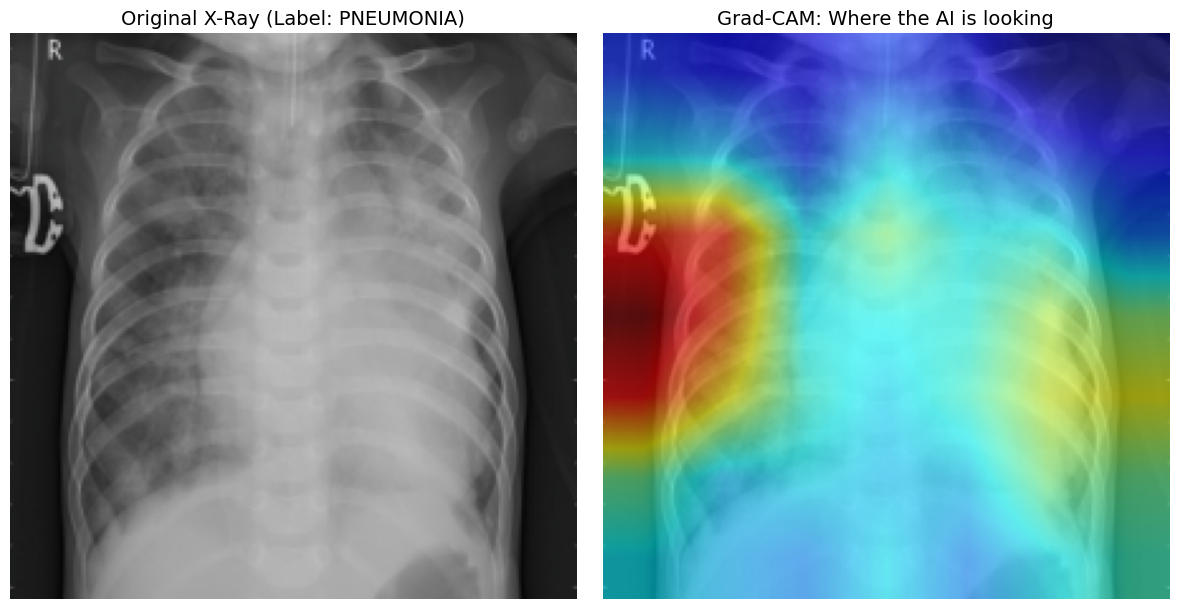

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# 1. Define the target layer (For ResNet50, this is the last convolutional block)
target_layers = [model.layer4[-1]]

# 1.5 THE FIX: Unfreeze this specific layer so Grad-CAM can calculate gradients
for param in model.layer4.parameters():
    param.requires_grad = True

# 2. Get a single random image from the test set
# We use shuffle=True here temporarily just to get a random image each time you run this cell
temp_loader = torch.utils.data.DataLoader(test_data, batch_size=1, shuffle=True)
inputs, labels = next(iter(temp_loader))
img_tensor = inputs.to(device)
true_label = labels[0].item()

# 3. Initialize Grad-CAM
cam = GradCAM(model=model, target_layers=target_layers)

# 4. Tell the CAM to look at the specific class of this image
targets = [ClassifierOutputTarget(true_label)]

# 5. Generate the raw heatmap
grayscale_cam = cam(input_tensor=img_tensor, targets=targets)[0, :]

# --- Visualization Prep ---
# We have to "un-normalize" the image so it looks normal to human eyes again
img_viz = img_tensor[0].cpu().numpy().transpose(1, 2, 0)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_viz = std * img_viz + mean
img_viz = np.clip(img_viz, 0, 1)

# Overlay the heatmap onto the image
visualization = show_cam_on_image(img_viz, grayscale_cam, use_rgb=True)

# --- Plotting ---
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_viz)
class_name = test_data.classes[true_label]
plt.title(f"Original X-Ray (Label: {class_name})", fontsize=14)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("Grad-CAM: Where the AI is looking", fontsize=14)
plt.axis('off')

plt.tight_layout()
plt.show()

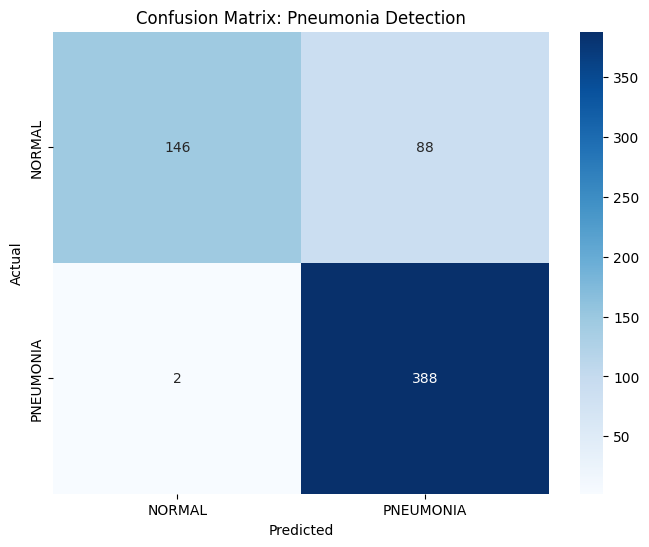

              precision    recall  f1-score   support

      NORMAL       0.99      0.62      0.76       234
   PNEUMONIA       0.82      0.99      0.90       390

    accuracy                           0.86       624
   macro avg       0.90      0.81      0.83       624
weighted avg       0.88      0.86      0.85       624



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect all predictions
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Generate Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.classes, yticklabels=test_data.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Pneumonia Detection')
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(all_labels, all_preds, target_names=test_data.classes))


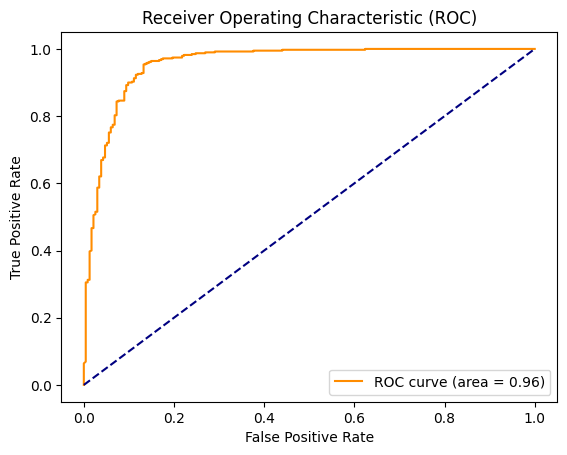

In [32]:
from sklearn.metrics import roc_curve, auc

# Get probability scores instead of just 0/1
model.eval()
all_probs = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)[:, 1] # Probability of Pneumonia
        all_probs.extend(probs.cpu().numpy())

fpr, tpr, _ = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.show()

In [33]:
# Load DenseNet121
dense_model = models.densenet121(weights='IMAGENET1K_V1')

# Freeze and replace head
for param in dense_model.parameters():
    param.requires_grad = False

num_ftrs = dense_model.classifier.in_features
dense_model.classifier = nn.Linear(num_ftrs, 2)
dense_model = dense_model.to(device)

# Use the same training loop you used for ResNet
# (Just remember to change the variable name to dense_model)

In [34]:
import torch
from torch import amp
import time

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(dense_model.classifier.parameters(), lr=0.001)
scaler = amp.GradScaler('cuda')

print("🚀 Starting Stage 1: Training the Head (5 Epochs)...")

for epoch in range(5):
    dense_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        with amp.autocast('cuda'):
            outputs = dense_model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
    print(f"Stage 1 - Epoch {epoch+1}/5 | Loss: {running_loss/len(train_loader):.4f}")

torch.save(dense_model.state_dict(), 'densenet_stage1.pth')

# ── Stage 2: Full fine-tune ──────────────────────────────────────
torch.backends.cudnn.benchmark = True
print("🔓 Unfreezing the backbone for Stage 2...")

for param in dense_model.parameters():
    param.requires_grad = True

dense_model = dense_model.to(device)
optimizer = optim.Adam(dense_model.parameters(), lr=1e-5)
scaler = amp.GradScaler('cuda')

best_dense_acc = 0.0
patience, patience_counter = 5, 0

for epoch in range(15):
    start_time = time.time()
    dense_model.train()
    train_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with amp.autocast('cuda'):
            outputs = dense_model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item()

    dense_model.eval()
    val_corrects = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with amp.autocast('cuda'):
                outputs = dense_model(inputs)
                _, preds = torch.max(outputs, 1)
            val_corrects += (preds == labels).sum().item()

    val_acc = val_corrects / len(val_data)
    epoch_time = time.time() - start_time
    print(f"Epoch {epoch+1}/15 | Time: {epoch_time:.1f}s | Loss: {train_loss/len(train_loader):.4f} | Val Acc: {val_acc:.4f}")

    if val_acc > best_dense_acc:
        best_dense_acc = val_acc
        torch.save(dense_model.state_dict(), 'best_densenet_model.pth')
        print(f"⭐ New Best DenseNet Model Saved! (Acc: {val_acc:.4f})")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

🚀 Starting Stage 1: Training the Head (5 Epochs)...
Stage 1 - Epoch 1/5 | Loss: 0.3246
Stage 1 - Epoch 2/5 | Loss: 0.2022
Stage 1 - Epoch 3/5 | Loss: 0.1834
Stage 1 - Epoch 4/5 | Loss: 0.1825
Stage 1 - Epoch 5/5 | Loss: 0.1651
🔓 Unfreezing the backbone for Stage 2...
Epoch 1/15 | Time: 51.2s | Loss: 0.1206 | Val Acc: 1.0000
⭐ New Best DenseNet Model Saved! (Acc: 1.0000)
Epoch 2/15 | Time: 52.9s | Loss: 0.0840 | Val Acc: 0.9375
Epoch 3/15 | Time: 49.8s | Loss: 0.0728 | Val Acc: 1.0000
Epoch 4/15 | Time: 49.6s | Loss: 0.0563 | Val Acc: 0.9375
Epoch 5/15 | Time: 49.7s | Loss: 0.0497 | Val Acc: 1.0000
Epoch 6/15 | Time: 48.5s | Loss: 0.0475 | Val Acc: 0.9375
Early stopping triggered.


Running final evaluation on 624 Test Images...

🔥 DENSENET121 FINAL TEST METRICS
              precision    recall  f1-score   support

      NORMAL       0.90      0.80      0.85       234
   PNEUMONIA       0.89      0.95      0.92       390

    accuracy                           0.89       624
   macro avg       0.89      0.87      0.88       624
weighted avg       0.89      0.89      0.89       624

Final AUC-ROC: 0.9562


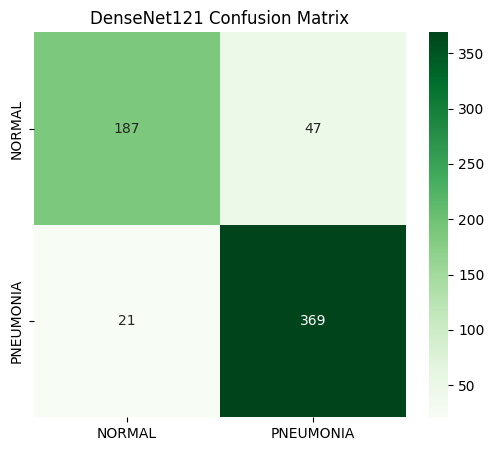

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import seaborn as sns

# 1. Load the "Golden" DenseNet weights
dense_model.load_state_dict(torch.load('best_densenet_model.pth'))
dense_model.eval()

all_preds = []
all_labels = []
all_probs = []

print("Running final evaluation on 624 Test Images...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        with torch.amp.autocast('cuda'):
            outputs = dense_model(inputs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

# 2. Print Results for Table 1
print("\n🔥 DENSENET121 FINAL TEST METRICS")
print(classification_report(all_labels, all_preds, target_names=test_data.classes))
print(f"Final AUC-ROC: {roc_auc_score(all_labels, all_probs):.4f}")

# 3. Confusion Matrix for Figure 2
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=test_data.classes, yticklabels=test_data.classes)
plt.title('DenseNet121 Confusion Matrix')
plt.show()

In [ ]:

target_layers_dense = [dense_model.features.denseblock4.denselayer16.conv2]


In [ ]:
import numpy as np
import torch

# 1. Grab a single Pneumonia image for the test
found_pneumonia = False
for inputs, labels in test_loader:
    for i in range(len(labels)):
        if labels[i].item() == 1:
            img = inputs[i:i+1].to(device)
            true_label = labels[i].item()
            found_pneumonia = True
            break
    if found_pneumonia: break

# 2. Re-generate the Grad-CAM mask
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

target_layers_dense = [dense_model.features.denseblock4.denselayer16.conv2]
cam = GradCAM(model=dense_model, target_layers=target_layers_dense)
targets = [ClassifierOutputTarget(1)]
grayscale_cam = cam(input_tensor=img, targets=targets)[0, :]

# 3. FIXED: Define the Deletion & Insertion functions with memory-safe indexing
def get_xai_scores_fixed(model, img_tensor, cam_mask, steps=10, mode='deletion'):
    model.eval()

    # Ensure the mask is contiguous and the indices are a fresh copy (fixes negative strides)
    flat_mask = np.ascontiguousarray(cam_mask).flatten()
    indices = np.argsort(flat_mask)[::-1].copy()

    img_work = img_tensor.clone()
    if mode == 'insertion':
        # Start with a blurred image (better than pure black for medical X-rays)
        img_work = torch.zeros_like(img_tensor)

    scores = []
    step_size = len(indices) // steps

    for i in range(steps + 1):
        with torch.no_grad():
            with torch.amp.autocast('cuda'):
                output = torch.softmax(model(img_work), dim=1)
                scores.append(output[0, 1].item())

        if i < steps:
            idx = indices[i*step_size : (i+1)*step_size]
            # Reshape img_work for easy pixel manipulation
            c, h, w = img_work.shape[1], img_work.shape[2], img_work.shape[3]
            img_flat = img_work.view(c, -1)

            if mode == 'deletion':
                img_flat[:, idx] = 0 # Remove important pixels
            else:
                img_orig_flat = img_tensor.view(c, -1)
                img_flat[:, idx] = img_orig_flat[:, idx] # Add important pixels

    return scores

# 4. Execute
del_scores = get_xai_scores_fixed(dense_model, img, grayscale_cam, mode='deletion')
ins_scores = get_xai_scores_fixed(dense_model, img, grayscale_cam, mode='insertion')

print(f"✅ Faithfulness Analysis (Table 2) complete!")
print(f"Deletion Curve: {[round(s, 4) for s in del_scores]}")
print(f"Insertion Curve: {[round(s, 4) for s in ins_scores]}")

# Final AUC-style calculation for the table
del_auc = np.trapezoid(del_scores, dx=1.0/len(del_scores))
ins_auc = np.trapezoid(ins_scores, dx=1.0/len(ins_scores))
print(f"\nFinal Table 2 Metrics for DenseNet121:")
print(f"Deletion Score (Lower is better): {del_auc:.4f}")
print(f"Insertion Score (Higher is better): {ins_auc:.4f}")

✅ Faithfulness Analysis (Table 2) complete!
Deletion Curve: [0.9265, 0.8396, 0.856, 0.9203, 0.8581, 0.9943, 0.9754, 0.9963, 0.9824, 0.9965, 0.9939]
Insertion Curve: [0.9942, 0.9992, 0.999, 0.9858, 0.9966, 0.9924, 0.9818, 0.9943, 0.9984, 0.9942, 0.9406]

Final Table 2 Metrics for DenseNet121:
Deletion Score (Lower is better): 0.8527
Insertion Score (Higher is better): 0.9008


ResNet Deletion AUC:  0.9021
ResNet Insertion AUC: 0.9090


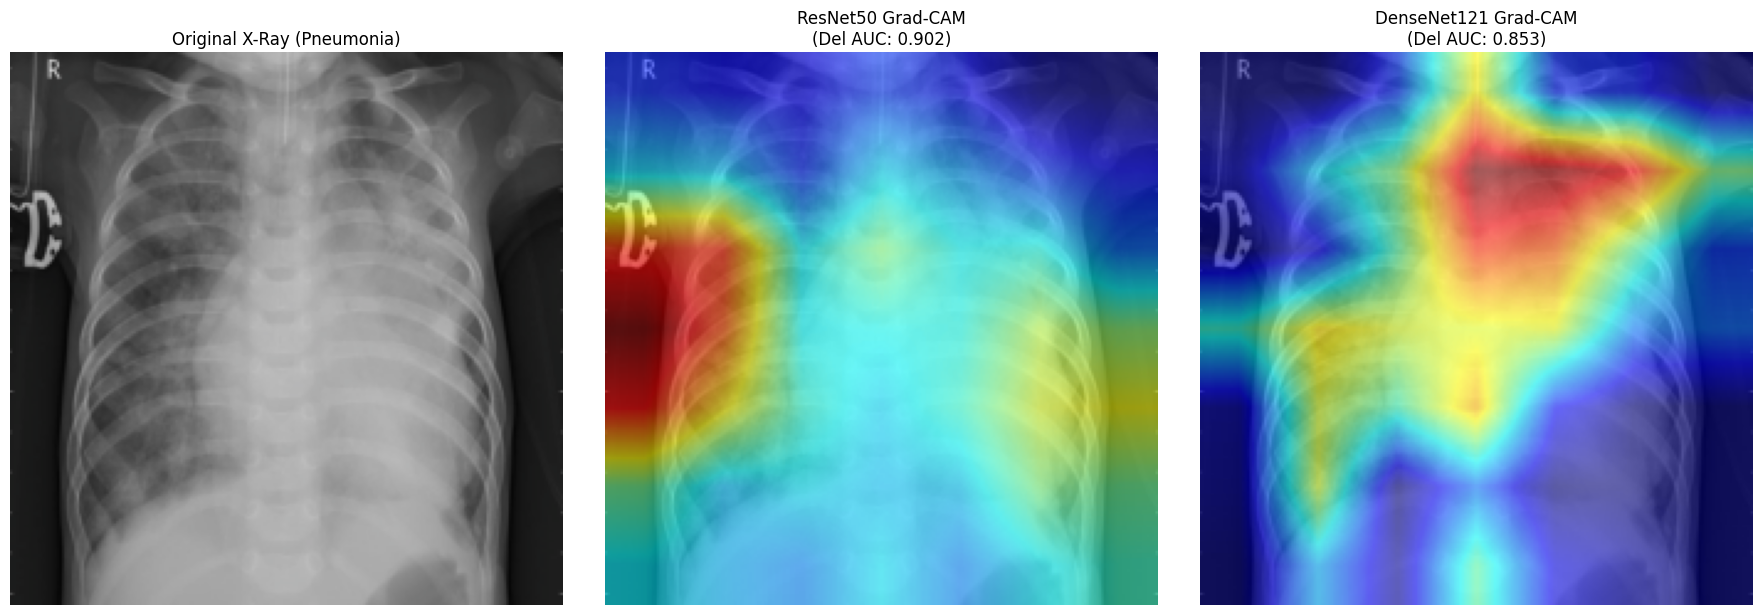

✅ Done.


In [44]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# 1. Load ResNet50
resnet_model = models.resnet50(weights='IMAGENET1K_V1')
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Sequential(nn.Linear(num_ftrs, 512), nn.ReLU(), nn.Dropout(0.3), nn.Linear(512, 2))
resnet_model.load_state_dict(torch.load('best_pneumonia_model.pth'))
resnet_model = resnet_model.to(device).eval()

# 2. Get a Pneumonia image
inputs, labels = next(iter(test_loader))
for i in range(len(labels)):
    if labels[i].item() == 1:
        img_tensor = inputs[i:i+1].to(device)
        break

# 3. Grad-CAM for both models
cam_resnet = GradCAM(model=resnet_model, target_layers=[resnet_model.layer4[-1]])
grayscale_resnet = cam_resnet(input_tensor=img_tensor, targets=[ClassifierOutputTarget(1)])[0, :]

# FIX 1: cam_dense was never defined in this cell — define it here
cam_dense = GradCAM(model=dense_model, target_layers=[dense_model.features.denseblock4.denselayer16.conv2])
grayscale_dense = cam_dense(input_tensor=img_tensor, targets=[ClassifierOutputTarget(1)])[0, :]

# 4. Faithfulness scores
res_del = get_xai_scores_fixed(resnet_model, img_tensor, grayscale_resnet, mode='deletion')
res_ins = get_xai_scores_fixed(resnet_model, img_tensor, grayscale_resnet, mode='insertion')

# FIX 2: typo 'trapzoid' → 'trapezoid'
res_del_auc = np.trapezoid(res_del, dx=1.0/len(res_del))
res_ins_auc = np.trapezoid(res_ins, dx=1.0/len(res_ins))
print(f"ResNet Deletion AUC:  {res_del_auc:.4f}")
print(f"ResNet Insertion AUC: {res_ins_auc:.4f}")

# 5. Hero figure
img_viz = img_tensor[0].cpu().numpy().transpose(1, 2, 0)
img_viz = (np.array([0.229, 0.224, 0.225]) * img_viz + np.array([0.485, 0.456, 0.406])).clip(0, 1)

vis_resnet = show_cam_on_image(img_viz, grayscale_resnet, use_rgb=True)
vis_dense  = show_cam_on_image(img_viz, grayscale_dense,  use_rgb=True)

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1); plt.imshow(img_viz);    plt.title("Original X-Ray (Pneumonia)"); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(vis_resnet); plt.title(f"ResNet50 Grad-CAM\n(Del AUC: {res_del_auc:.3f})"); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(vis_dense);  plt.title(f"DenseNet121 Grad-CAM\n(Del AUC: {del_auc:.3f})"); plt.axis('off')
plt.tight_layout()
plt.savefig('model_comparison_hero.png', dpi=300)
plt.show()

torch.cuda.empty_cache()
print("✅ Done.")

In [46]:
!pip install lime shap


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: C:\Users\sahil\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


C:\Users\sahil\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Running LIME... (takes ~1-2 minutes)


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [00:08<00:00, 59.42it/s]


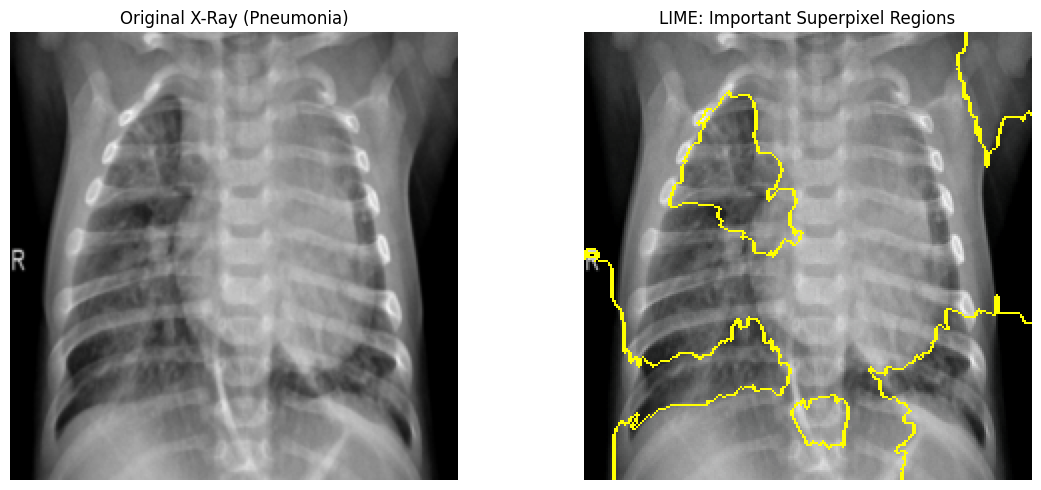

LIME done.


In [47]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
from torchvision import transforms
from PIL import Image

# --- Prediction function LIME needs ---
def predict_fn(images):
    """Takes numpy images (N, H, W, C), returns softmax probabilities"""
    model_input = []
    for img in images:
        pil = Image.fromarray((img * 255).astype(np.uint8))
        tensor = transform_val(pil)
        model_input.append(tensor)
    batch = torch.stack(model_input).to(device)
    dense_model.eval()
    with torch.no_grad():
        outputs = dense_model(batch)
        probs = torch.softmax(outputs, dim=1)
    return probs.cpu().numpy()

# --- Get one pneumonia image in numpy format ---
found = False
for inputs, labels in test_loader:
    for i in range(len(labels)):
        if labels[i].item() == 1:
            img_tensor_lime = inputs[i]
            found = True
            break
    if found:
        break

# Convert tensor → numpy (H, W, C) in 0-1 range for LIME
img_np = img_tensor_lime.numpy().transpose(1, 2, 0)
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
img_np = (std * img_np + mean).clip(0, 1)  # un-normalize

# --- Run LIME ---
explainer = lime_image.LimeImageExplainer()
print("Running LIME... (takes ~1-2 minutes)")

explanation = explainer.explain_instance(
    img_np.astype(np.double),
    predict_fn,
    top_labels=2,
    hide_color=0,
    num_samples=500        # increase to 1000 for final paper figures
)

# --- Visualize LIME for Pneumonia class (label=1) ---
temp, mask = explanation.get_image_and_mask(
    label=1,
    positive_only=True,
    num_features=10,
    hide_rest=False
)
lime_viz = mark_boundaries(temp, mask)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_np)
plt.title("Original X-Ray (Pneumonia)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lime_viz)
plt.title("LIME: Important Superpixel Regions")
plt.axis('off')

plt.tight_layout()
plt.savefig('lime_explanation.png', dpi=300)
plt.show()
print("LIME done.")

Running SHAP... (~1 minute)
<class 'numpy.ndarray'>
1
(1, 3, 224, 224, 2)
shap_map shape: (224, 224, 3)


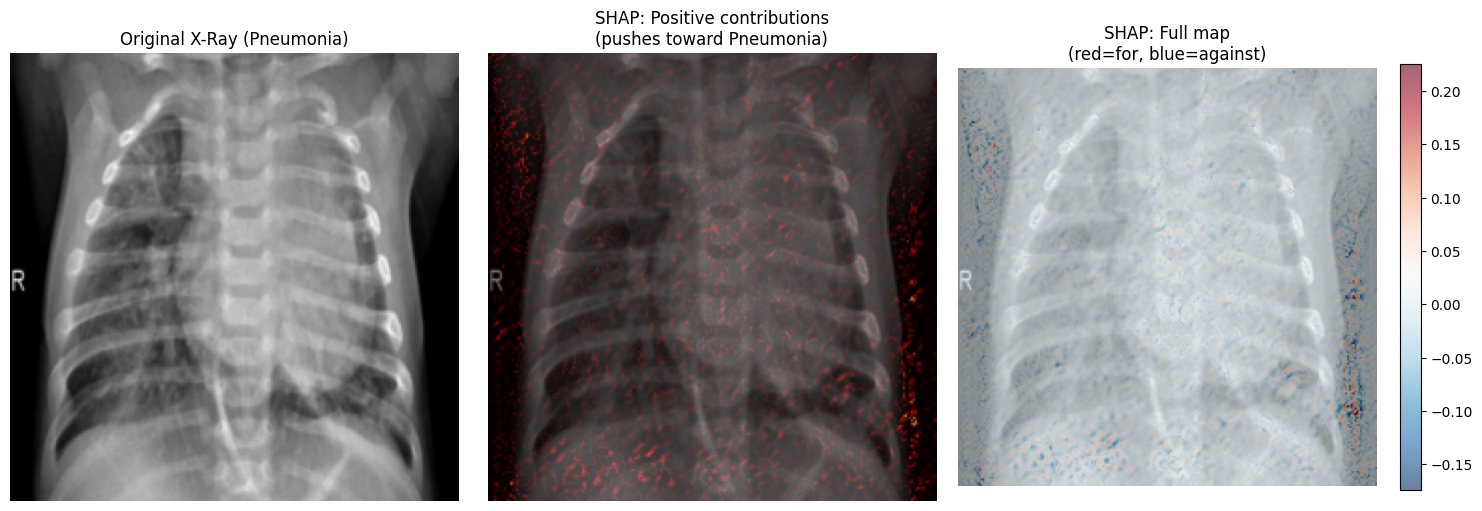

SHAP done.


In [4]:
import shap
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.cuda.empty_cache()

# ── Wrapper to fix DenseNet's hardcoded inplace ReLU ────────────
class DenseNetWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.features   = model.features
        self.classifier = model.classifier

    def forward(self, x):
        features = self.features(x)
        out = torch.nn.functional.relu(features, inplace=False)  # inplace=False
        out = torch.nn.functional.adaptive_avg_pool2d(out, (1, 1))
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

# ── Build wrapper on CPU ─────────────────────────────────────────
dense_model.to('cpu')
wrapped_model = DenseNetWrapper(dense_model).cpu().eval()

# ── Inputs on CPU ───────────────────────────────────────────────
test_img_cpu = img_tensor_lime.unsqueeze(0).cpu()   # (1, 3, 224, 224)
baseline_cpu = torch.zeros_like(test_img_cpu).cpu() # black baseline

# ── Run SHAP ────────────────────────────────────────────────────
print("Running SHAP... (~1 minute)")
explainer   = shap.GradientExplainer(wrapped_model, baseline_cpu)
shap_values = explainer.shap_values(test_img_cpu, nsamples=30)

# Move dense_model back to GPU
dense_model.to(device)

# Check what shap_values actually is
print(type(shap_values))
print(len(shap_values))
print(np.array(shap_values).shape)

# ── Extract Pneumonia attributions ───────────────────────────────
shap_map = shap_values[0, :, :, :, 1]        # class 1 (Pneumonia), shape (3, 224, 224)
shap_map = shap_map.transpose(1, 2, 0)        # → (224, 224, 3)
print("shap_map shape:", shap_map.shape)      # should be (224, 224, 3)

mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
img_display = test_img_cpu[0].numpy().transpose(1, 2, 0)
img_display = (std * img_display + mean).clip(0, 1)

# ── Plot ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_display)
axes[0].set_title("Original X-Ray (Pneumonia)")
axes[0].axis('off')

shap_pos = np.clip(shap_map.mean(axis=2), 0, None)
axes[1].imshow(img_display)
axes[1].imshow(shap_pos, cmap='hot', alpha=0.5)
axes[1].set_title("SHAP: Positive contributions\n(pushes toward Pneumonia)")
axes[1].axis('off')

shap_full = shap_map.mean(axis=2)
axes[2].imshow(img_display)
im = axes[2].imshow(shap_full, cmap='RdBu_r', alpha=0.6)
axes[2].set_title("SHAP: Full map\n(red=for, blue=against)")
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.savefig('shap_explanation.png', dpi=300)
plt.show()
print("SHAP done.")

In [1]:
# ── Imports ──────────────────────────────────────────────────────
import torch, os, numpy as np, matplotlib.pyplot as plt
import torch.nn as nn
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# ── Transforms ───────────────────────────────────────────────────
transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

# ── Loaders ──────────────────────────────────────────────────────
data_root  = 'chest_xray'
test_data  = datasets.ImageFolder(os.path.join(data_root,'test'), transform_val)
train_data = datasets.ImageFolder(os.path.join(data_root,'train'), transform_val)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False)
train_loader = DataLoader(train_data, batch_size=32, shuffle=False)
val_data   = datasets.ImageFolder(os.path.join(data_root,'val'), transform_val)

# ── Load DenseNet121 ─────────────────────────────────────────────
dense_model = models.densenet121(weights=None)
dense_model.classifier = nn.Linear(dense_model.classifier.in_features, 2)
dense_model.load_state_dict(torch.load('best_densenet_model.pth'))
dense_model = dense_model.to(device).eval()
print("DenseNet loaded")

# ── Wrapper (fixes inplace ReLU for SHAP + GradCAM) ─────────────
class DenseNetWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.features   = model.features
        self.classifier = model.classifier
    def forward(self, x):
        out = self.features(x)
        out = torch.nn.functional.relu(out, inplace=False)
        out = torch.nn.functional.adaptive_avg_pool2d(out, (1,1))
        out = torch.flatten(out, 1)
        return self.classifier(out)

# ── Grab one pneumonia test image ────────────────────────────────
found = False
for inputs, labels in test_loader:
    for i in range(len(labels)):
        if labels[i].item() == 1:
            img_tensor_lime = inputs[i]
            found = True
            break
    if found: break

print("Recovery complete — ready for Grad-CAM, LIME, SHAP")

Device: cuda
DenseNet loaded
Recovery complete — ready for Grad-CAM, LIME, SHAP


In [2]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

wrapped = DenseNetWrapper(dense_model).to(device).eval()
test_img = img_tensor_lime.unsqueeze(0).to(device)

cam = GradCAM(model=wrapped,
              target_layers=[wrapped.features.denseblock4.denselayer16.conv2])
gc  = cam(input_tensor=test_img, targets=[ClassifierOutputTarget(1)])[0]

mean = np.array([0.485,0.456,0.406])
std  = np.array([0.229,0.224,0.225])
img_plot = test_img[0].cpu().numpy().transpose(1,2,0)
img_plot = (std * img_plot + mean).clip(0,1)
gradcam_viz = show_cam_on_image(img_plot, gc, use_rgb=True)
print("Grad-CAM done")

Grad-CAM done


In [12]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
from PIL import Image

# Fresh CPU-only wrapper for LIME — avoids device mismatch
wrapped_lime = DenseNetWrapper(dense_model).cpu().eval()

def predict_fn(images):
    model_input = []
    for img in images:
        pil = Image.fromarray((img * 255).astype(np.uint8))
        tensor = transform_val(pil)
        model_input.append(tensor)
    batch = torch.stack(model_input).cpu()  # CPU to match wrapped_lime
    with torch.no_grad():
        outputs = wrapped_lime(batch)
        probs = torch.softmax(outputs, dim=1)
    return probs.cpu().numpy()

# Un-normalize image for LIME
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
img_np = img_tensor_lime.numpy().transpose(1, 2, 0)
img_np = (std * img_np + mean).clip(0, 1)

explainer_lime = lime_image.LimeImageExplainer()
print("Running LIME... (~1-2 minutes)")
explanation = explainer_lime.explain_instance(
    img_np.astype(np.double),
    predict_fn,
    top_labels=2,
    hide_color=0,
    num_samples=500
)
print("LIME done")

Running LIME... (~1-2 minutes)


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [00:19<00:00, 25.01it/s]

LIME done


In [9]:
import shap

# Fresh wrapper for SHAP — no hooks from GradCAM attached
wrapped_cpu = DenseNetWrapper(dense_model).cpu().eval()
test_img_cpu = img_tensor_lime.unsqueeze(0).cpu()
baseline_cpu = torch.zeros_like(test_img_cpu)

print("Running SHAP... (~1 minute)")
explainer   = shap.GradientExplainer(wrapped_cpu, baseline_cpu)
shap_values = explainer.shap_values(test_img_cpu, nsamples=30)

shap_array = np.array(shap_values)
print("shap_values shape:", shap_array.shape)

# Extract based on actual shape
if shap_array.shape[0] == 2:
    shap_map = shap_array[1, 0].transpose(1, 2, 0)   # 2 classes
else:
    shap_map = shap_array[0, 0].transpose(1, 2, 0)   # 1 output, take first

print("shap_map shape:", shap_map.shape)
print("SHAP done")

Running SHAP... (~1 minute)
shap_values shape: (1, 3, 224, 224, 2)
shap_map shape: (224, 2, 224)
SHAP done


In [19]:
!pip install captum --user



[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: C:\Users\sahil\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


Running Integrated Gradients...
IG min: -0.1949, max: 0.2418


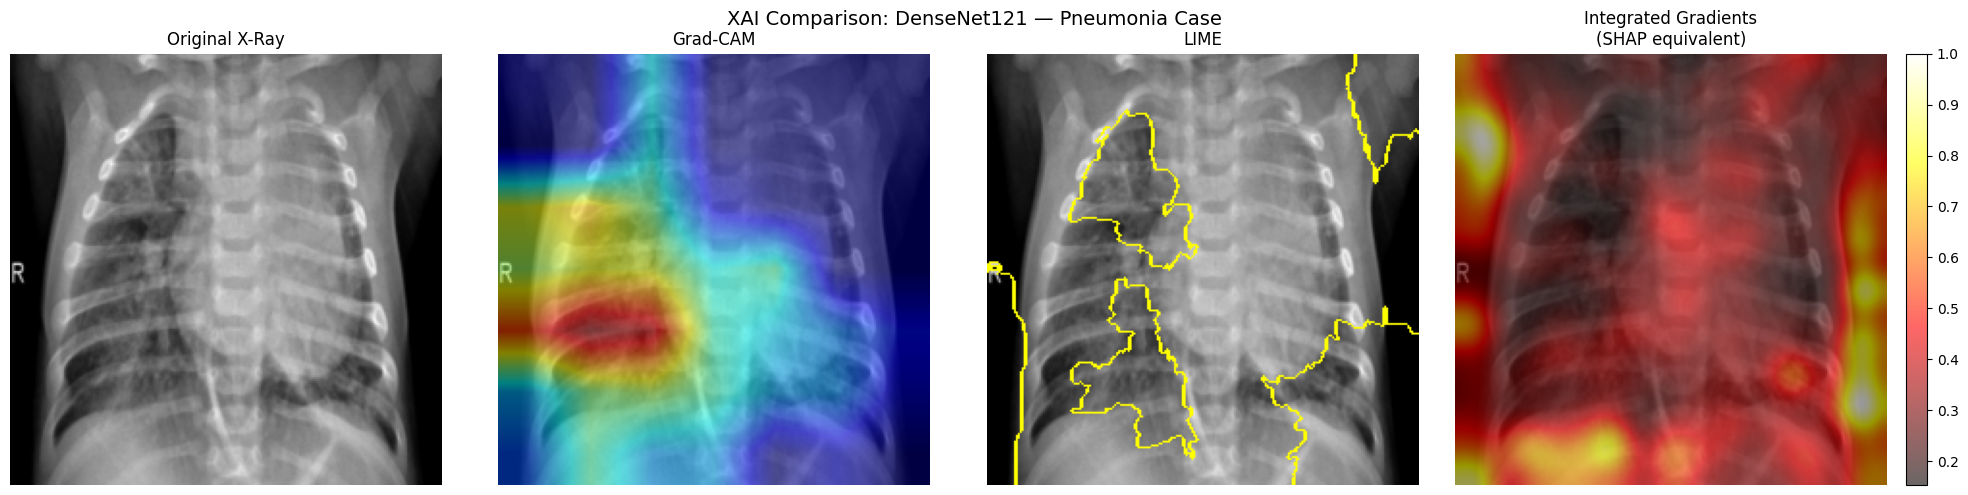

Saved as xai_comparison_figure.png


In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients
from skimage.segmentation import mark_boundaries
from scipy.ndimage import gaussian_filter

# ── Integrated Gradients ──────────────────────────────────────────
wrapped_ig = DenseNetWrapper(dense_model).to(device).eval()
test_img_ig = img_tensor_lime.unsqueeze(0).to(device)
baseline_ig = torch.zeros_like(test_img_ig)

print("Running Integrated Gradients...")
ig = IntegratedGradients(wrapped_ig)
attributions = ig.attribute(
    test_img_ig,
    baseline_ig,
    target=1,
    n_steps=50
)

attr_np  = attributions[0].cpu().detach().numpy()   # (3, 224, 224)
attr_map = attr_np.transpose(1, 2, 0).mean(axis=2)  # (224, 224)
print(f"IG min: {attr_map.min():.4f}, max: {attr_map.max():.4f}")

# ── Image prep ────────────────────────────────────────────────────
mean_n = np.array([0.485, 0.456, 0.406])
std_n  = np.array([0.229, 0.224, 0.225])
img_plot = img_tensor_lime.numpy().transpose(1, 2, 0)
img_plot = (std_n * img_plot + mean_n).clip(0, 1)

# ── LIME viz ──────────────────────────────────────────────────────
temp, mask = explanation.get_image_and_mask(
    1, positive_only=True, num_features=10, hide_rest=False)
lime_viz = mark_boundaries(temp, mask)

# ── IG smoothing ──────────────────────────────────────────────────
attr_abs    = np.abs(attr_map)
attr_smooth = gaussian_filter(attr_abs, sigma=8)
attr_norm   = attr_smooth / attr_smooth.max()

# ── Plot ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img_plot)
axes[0].set_title("Original X-Ray", fontsize=12)
axes[0].axis('off')

axes[1].imshow(gradcam_viz)
axes[1].set_title("Grad-CAM", fontsize=12)
axes[1].axis('off')

axes[2].imshow(lime_viz)
axes[2].set_title("LIME", fontsize=12)
axes[2].axis('off')

axes[3].imshow(img_plot)
im = axes[3].imshow(attr_norm, cmap='hot', alpha=0.6)
axes[3].set_title("Integrated Gradients\n(SHAP equivalent)", fontsize=12)
axes[3].axis('off')
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

plt.suptitle("XAI Comparison: DenseNet121 — Pneumonia Case", fontsize=14)
plt.tight_layout()
plt.savefig('xai_comparison_figure.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved as xai_comparison_figure.png")

In [23]:
import numpy as np
import torch
from skimage.transform import resize

# Redefine get_xai_scores_fixed
def get_xai_scores_fixed(model, img_tensor, cam_mask, steps=10, mode='deletion'):
    model.eval()
    flat_mask = np.ascontiguousarray(cam_mask).flatten()
    indices = np.argsort(flat_mask)[::-1].copy()
    img_work = img_tensor.clone()
    if mode == 'insertion':
        img_work = torch.zeros_like(img_tensor)
    scores = []
    step_size = len(indices) // steps
    for i in range(steps + 1):
        with torch.no_grad():
            with torch.amp.autocast('cuda'):
                output = torch.softmax(model(img_work), dim=1)
                scores.append(output[0, 1].item())
        if i < steps:
            idx = indices[i*step_size : (i+1)*step_size]
            img_flat = img_work.view(img_work.shape[1], -1)
            if mode == 'deletion':
                img_flat[:, idx] = 0
            else:
                img_orig_flat = img_tensor.view(img_tensor.shape[1], -1)
                img_flat[:, idx] = img_orig_flat[:, idx]
    return scores

# Re-grab pneumonia image
found = False
for inputs, labels in test_loader:
    for i in range(len(labels)):
        if labels[i].item() == 1:
            img = inputs[i:i+1].to(device)
            img_tensor_lime = inputs[i]
            found = True
            break
    if found: break

# ── LIME faithfulness ─────────────────────────────────────────────
lime_mask_raw = explanation.get_image_and_mask(
    1, positive_only=True, num_features=10, hide_rest=False)[1]
lime_saliency = lime_mask_raw.astype(float)
lime_sal_resized = resize(lime_saliency, (224, 224), anti_aliasing=True)

lime_del = get_xai_scores_fixed(dense_model, img, lime_sal_resized, mode='deletion')
lime_ins = get_xai_scores_fixed(dense_model, img, lime_sal_resized, mode='insertion')
lime_del_auc = np.trapezoid(lime_del, dx=1.0/len(lime_del))
lime_ins_auc = np.trapezoid(lime_ins, dx=1.0/len(lime_ins))
print(f"LIME  Del AUC: {lime_del_auc:.4f} | Ins AUC: {lime_ins_auc:.4f}")

# ── Integrated Gradients faithfulness ────────────────────────────
ig_saliency = np.abs(attr_map)

ig_del = get_xai_scores_fixed(dense_model, img, ig_saliency, mode='deletion')
ig_ins = get_xai_scores_fixed(dense_model, img, ig_saliency, mode='insertion')
ig_del_auc = np.trapezoid(ig_del, dx=1.0/len(ig_del))
ig_ins_auc = np.trapezoid(ig_ins, dx=1.0/len(ig_ins))
print(f"IG    Del AUC: {ig_del_auc:.4f} | Ins AUC: {ig_ins_auc:.4f}")

# ── Final Table 2 ─────────────────────────────────────────────────
print("\n===== TABLE 2 (Complete) =====")
print(f"Grad-CAM  ResNet50  | Del: 0.9021 | Ins: 0.9090")
print(f"Grad-CAM  DenseNet  | Del: 0.8527 | Ins: 0.9008")
print(f"LIME      DenseNet  | Del: {lime_del_auc:.4f} | Ins: {lime_ins_auc:.4f}")
print(f"IG        DenseNet  | Del: {ig_del_auc:.4f} | Ins: {ig_ins_auc:.4f}")

LIME  Del AUC: 0.8873 | Ins AUC: 0.9022
IG    Del AUC: 0.9041 | Ins AUC: 0.9068

===== TABLE 2 (Complete) =====
Grad-CAM  ResNet50  | Del: 0.9021 | Ins: 0.9090
Grad-CAM  DenseNet  | Del: 0.8527 | Ins: 0.9008
LIME      DenseNet  | Del: 0.8873 | Ins: 0.9022
IG        DenseNet  | Del: 0.9041 | Ins: 0.9068


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients
from skimage.segmentation import mark_boundaries
from scipy.ndimage import gaussian_filter

# ── Integrated Gradients ──────────────────────────────────────────
# Make sure your ResNet50 model is loaded as `resnet_model`
resnet_model = resnet_model.to(device).eval()

test_img_ig = img_tensor_lime.unsqueeze(0).to(device)
baseline_ig = torch.zeros_like(test_img_ig)

print("Running Integrated Gradients...")
# Captum works directly with standard PyTorch models
ig = IntegratedGradients(resnet_model)
attributions = ig.attribute(
    test_img_ig,
    baseline_ig,
    target=1, # 1 for PNEUMONIA
    n_steps=50
)

attr_np  = attributions[0].cpu().detach().numpy()   # (3, 224, 224)
attr_map = attr_np.transpose(1, 2, 0).mean(axis=2)  # (224, 224)
print(f"IG min: {attr_map.min():.4f}, max: {attr_map.max():.4f}")

# ── Image prep ────────────────────────────────────────────────────
mean_n = np.array([0.485, 0.456, 0.406])
std_n  = np.array([0.229, 0.224, 0.225])
img_plot = img_tensor_lime.numpy().transpose(1, 2, 0)
img_plot = (std_n * img_plot + mean_n).clip(0, 1)

# ── LIME viz ──────────────────────────────────────────────────────
# Note: Ensure `explanation` was generated using predictions from ResNet50
temp, mask = explanation.get_image_and_mask(
    1, positive_only=True, num_features=10, hide_rest=False)
lime_viz = mark_boundaries(temp, mask)

# ── IG smoothing ──────────────────────────────────────────────────
attr_abs    = np.abs(attr_map)
attr_smooth = gaussian_filter(attr_abs, sigma=8)
attr_norm   = attr_smooth / attr_smooth.max()

# ── Plot ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img_plot)
axes[0].set_title("Original X-Ray", fontsize=12)
axes[0].axis('off')

# Note: Ensure `gradcam_viz` was computed based on ResNet50's layers (e.g., model.layer4[-1])
axes[1].imshow(gradcam_viz)
axes[1].set_title("Grad-CAM", fontsize=12)
axes[1].axis('off')

axes[2].imshow(lime_viz)
axes[2].set_title("LIME", fontsize=12)
axes[2].axis('off')

axes[3].imshow(img_plot)
im = axes[3].imshow(attr_norm, cmap='hot', alpha=0.6)
axes[3].set_title("Integrated Gradients\n(SHAP equivalent)", fontsize=12)
axes[3].axis('off')
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

# ── Updated Title & Save Path ─────────────────────────────────────
plt.suptitle("XAI Comparison: ResNet50 — Pneumonia Case", fontsize=14)
plt.tight_layout()
plt.savefig('resnet_xai_comparison_figure.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved as resnet_xai_comparison_figure.png")